# Baseline SEM defect classifier

## Archived thesis implementation

This notebook trains a classification head on a frozen ResNet50V2 backbone using original SEM images from Classes 1, 3, and 4 of the Carinthia dataset. It provides the baseline for comparison with VAE-augmented training configurations.

This publication copy changes documentation and comments only. Executable statements, configuration, and saved outputs are preserved. No training or evaluation was rerun during this cleanup. Saved outputs are historical results, not outputs from a newly validated environment.

## Before running

Execution is not required to read this notebook. Google Drive paths refer to the original workspace. Training can overwrite model files; plotting cells can overwrite figures. Preserve original artifacts before any deliberate rerun.

## Interpretation

The test subset is reused for validation-based checkpoint selection and evaluation. The conformal threshold uses an interpolated percentile without the finite-sample correction described in the thesis. Treat the results as exploratory archived findings rather than an unbiased benchmark or a verification of a nominal coverage guarantee.


## 1. Environment and plotting defaults

Install dependencies, import libraries, and mount Google Drive. The recorded package output belongs to the original run. Seeds are set to support repeatability; they do not by themselves guarantee identical results across environments.


In [ ]:
# --- Step 1: Setup and Libraries ---
!pip install mapie "numpy<2.2.0,>=1.26.0"

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import seaborn as sns
import pandas as pd
import os
import shutil
import pathlib
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve, average_precision_score, cohen_kappa_score
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# --- Global Plot Style (scientific, no bright colors) ---
mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.linestyle': ':',
    'grid.alpha': 0.5,
    'lines.linewidth': 1.8,
    'figure.dpi': 150,
})
COLORS = ['#2c7bb6', '#d7191c', '#1a9641', '#fdae61']  # Plot palette used in the original experiment

print("TensorFlow Version:", tf.__version__)
print("Setup complete.")

# Set random seeds; cross-environment reproducibility is not guaranteed.
import random
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print(f"Global seed set to {SEED} – results are now reproducible.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.4/216.4 kB 4.8 MB/s eta 0:00:00
Mounted at /content/drive
TensorFlow Version: 2.19.0
Setup complete.
Global seed set to 42 – results are now reproducible.


## 2. Load and split original images

Load Classes 1, 3, and 4 and create stratified 70/15/15 training, calibration, and test subsets. No VAE-generated images are used. File paths are not explicitly sorted before splitting, so the seed alone does not establish stable file-level partitions. The local working folder is replaced when this cell runs.


--- DIAGNOSIS ---
OK: /content/drive/MyDrive/CarinthiaDataset/classified_images

Data split (70/15/15):
  Training set:    3046 images
  Calibration set: 653  images
  Test set:        653  images


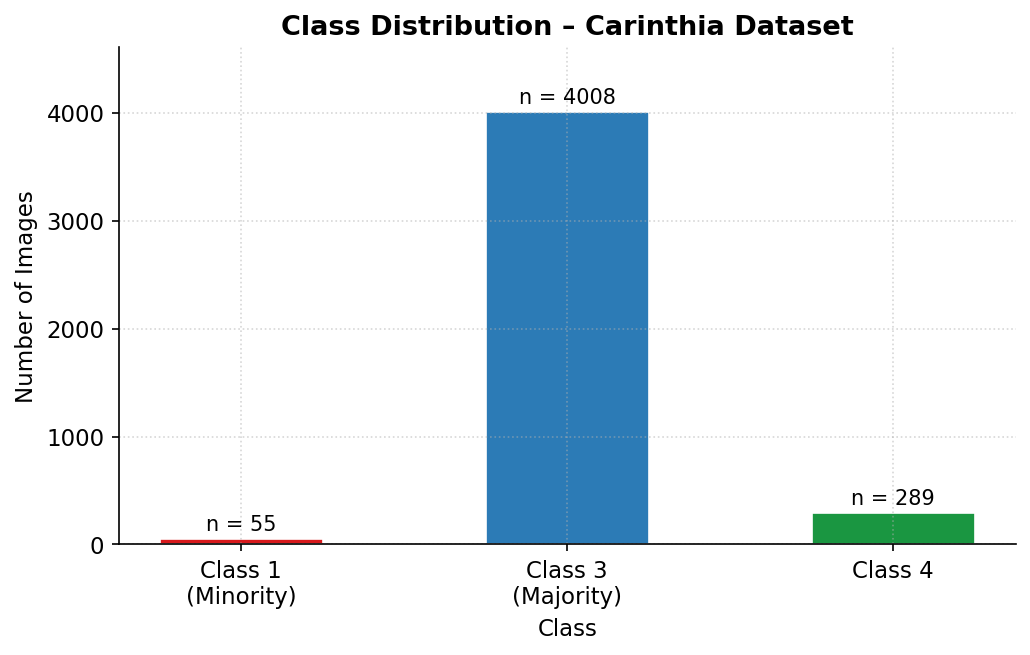

Figure saved: /content/drive/MyDrive/CarinthiaDataset/figures/fig_class_distribution.png


In [ ]:
# --- Step 2: Data Loading and Splitting (70/15/15) ---
import pathlib, shutil, os
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

base_path     = pathlib.Path('/content/drive/MyDrive')
dataset_path  = base_path / 'CarinthiaDataset'
images_path   = dataset_path / 'classified_images'

print("--- DIAGNOSIS ---")
if not dataset_path.exists():
    raise FileNotFoundError(f"Dataset folder not found: {dataset_path}")
print(f"OK: {images_path}")

target_classes = ['class_1', 'class_3', 'class_4']
local_data_dir = pathlib.Path('/content/filtered_data')
if local_data_dir.exists(): shutil.rmtree(local_data_dir)
local_data_dir.mkdir()

for cls in target_classes:
    src = images_path / cls
    shutil.copytree(src, local_data_dir / cls)

all_image_paths  = [str(p) for p in local_data_dir.glob('*/*')]
class_names      = sorted([d.name for d in local_data_dir.iterdir() if d.is_dir()])
class_indices    = {name: i for i, name in enumerate(class_names)}
all_image_labels = [class_indices[pathlib.Path(p).parent.name] for p in all_image_paths]

X_train, X_temp, y_train, y_temp = train_test_split(
    all_image_paths, all_image_labels, test_size=0.30,
    stratify=all_image_labels, random_state=123)
X_cal, X_test, y_cal, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50,
    stratify=y_temp, random_state=123)

IMG_SIZE   = (224, 224)
BATCH_SIZE = 32

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    return img, label

train_dataset = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(len(X_train)).batch(BATCH_SIZE)
    .cache().prefetch(tf.data.AUTOTUNE))
cal_dataset = (tf.data.Dataset.from_tensor_slices((X_cal, y_cal))
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE).cache().prefetch(tf.data.AUTOTUNE))
test_dataset = (tf.data.Dataset.from_tensor_slices((X_test, y_test))
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE).cache().prefetch(tf.data.AUTOTUNE))

print(f"\nData split (70/15/15):")
print(f"  Training set:    {len(X_train)} images")
print(f"  Calibration set: {len(X_cal)}  images")
print(f"  Test set:        {len(X_test)}  images")

# --- Figure: Class Distribution (Chapter 4.1) ---
class_counts = {cls: sum(1 for p in local_data_dir.glob(f'{cls}/*')) for cls in class_names}
labels_short = ['Class 1\n(Minority)', 'Class 3\n(Majority)', 'Class 4']
counts       = [class_counts[c] for c in class_names]
bar_colors   = ['#d7191c', '#2c7bb6', '#1a9641']

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(labels_short, counts, color=bar_colors, width=0.5, edgecolor='white', linewidth=0.8)
for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 40,
            f'n = {count}', ha='center', va='bottom', fontsize=10)
ax.set_title('Class Distribution – Carinthia Dataset', fontweight='bold')
ax.set_xlabel('Class')
ax.set_ylabel('Number of Images')
ax.set_ylim(0, max(counts) * 1.15)
plt.tight_layout()
save_path = str(dataset_path / 'figures' / 'fig_class_distribution.png')
os.makedirs(os.path.dirname(save_path), exist_ok=True)
plt.savefig(save_path, bbox_inches='tight')
plt.show()
print(f"Figure saved: {save_path}")


## 3. Define the baseline classifier

Apply geometric and photometric augmentation during training, then preprocess inputs for a frozen ImageNet-pretrained ResNet50V2 backbone. Train a classification head with global average pooling, dropout, and a three-class softmax output. The backbone is not fine-tuned.


In [ ]:
# --- Step 3: Data Augmentation Pipeline and CNN Model ---
num_classes = len(class_names)

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.3),
    layers.RandomZoom(0.2),
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.2),
    layers.GaussianNoise(0.1)
], name="data_augmentation")

base_model = tf.keras.applications.ResNet50V2(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    include_top=False, weights='imagenet')
base_model.trainable = False

inputs  = keras.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x       = data_augmentation(inputs)
x       = tf.keras.applications.resnet_v2.preprocess_input(x)
x       = base_model(x, training=False)
x       = layers.GlobalAveragePooling2D()(x)
x       = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)

model = keras.Model(inputs, outputs, name="Baseline_ResNet50V2")
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy'])
model.summary()


94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "Baseline_ResNet50V2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 7, 7, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         6,147 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,570,947 (89.92 MB)

 Trainable params: 6,147 (24.01 KB)

 Non-trainable params: 23,564,800 (89.89 MB)

## 4. Compute class weights

Compute balanced class weights from the training labels to increase the loss contribution of underrepresented classes.


In [ ]:
# --- Step 4: Class Weights ---
from sklearn.utils.class_weight import compute_class_weight

train_labels  = np.concatenate([y for x, y in train_dataset], axis=0)
weights       = compute_class_weight('balanced', classes=np.unique(train_labels), y=train_labels)
class_weights = dict(enumerate(weights))

print("Class weights (higher = more important):")
for i, name in enumerate(class_names):
    print(f"  {name}: {class_weights[i]:.2f}")


Class weights (higher = more important):
  class_1: 26.03
  class_3: 0.36
  class_4: 5.03


## 5. Train and save the classifier

Train for up to 100 epochs with early stopping and checkpoint selection. In this archived implementation, the test subset is also used as validation data for model selection. Consequently, the subsequent evaluation is not on an untouched test subset. Running this cell can overwrite saved model files.


In [ ]:
# Archived protocol: the test subset is reused for validation-based model selection.
# Running this cell can overwrite the original model files on Google Drive.
# --- Step 5: Training ---
checkpoint_path = '/content/drive/MyDrive/CarinthiaDataset/models/baseline_best.keras'
os.makedirs(os.path.dirname(checkpoint_path), exist_ok=True)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=10,
        restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path, save_best_only=True,
        monitor='val_loss', verbose=1)
]

print("Starting training...")
history = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=100,
    class_weight=class_weights,
    callbacks=callbacks
)

# --- Save final model explicitly (reload anytime without retraining) ---
final_path = '/content/drive/MyDrive/CarinthiaDataset/models/baseline_final.keras'
model.save(final_path)
print(f"\nModel saved to Drive: {final_path}")
print("To reload in a new session without retraining:")
print(f"  model = keras.models.load_model('{final_path}')")


Starting training...
Epoch 1/100
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.7876 - loss: 0.6174
Epoch 1: val_loss improved from None to 0.25390, saving model to /content/drive/MyDrive/CarinthiaDataset/models/baseline_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/CarinthiaDataset/models/baseline_best.keras
96/96 ━━━━━━━━━━━━━━━━━━━━ 32s 188ms/step - accuracy: 0.8894 - loss: 0.3174 - val_accuracy: 0.9112 - val_loss: 0.2539
Epoch 2/100
95/96 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.9525 - loss: 0.1235
Epoch 2: val_loss improved from 0.25390 to 0.10104, saving model to /content/drive/MyDrive/CarinthiaDataset/models/baseline_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/CarinthiaDataset/models/baseline_best.keras
96/96 ━━━━━━━━━━━━━━━━━━━━ 30s 139ms/step - accuracy: 0.9593 - loss: 0.1038 - val_accuracy: 0.9694 - val_loss: 0.1010
Epoch 3/100
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 0.9549 - loss: 0.0895
Epoch 3: va

## 6. Inspect learning curves

Plot recorded training and validation accuracy and loss. Here, validation refers to the test subset reused during model selection. The best epoch is identified using its loss.


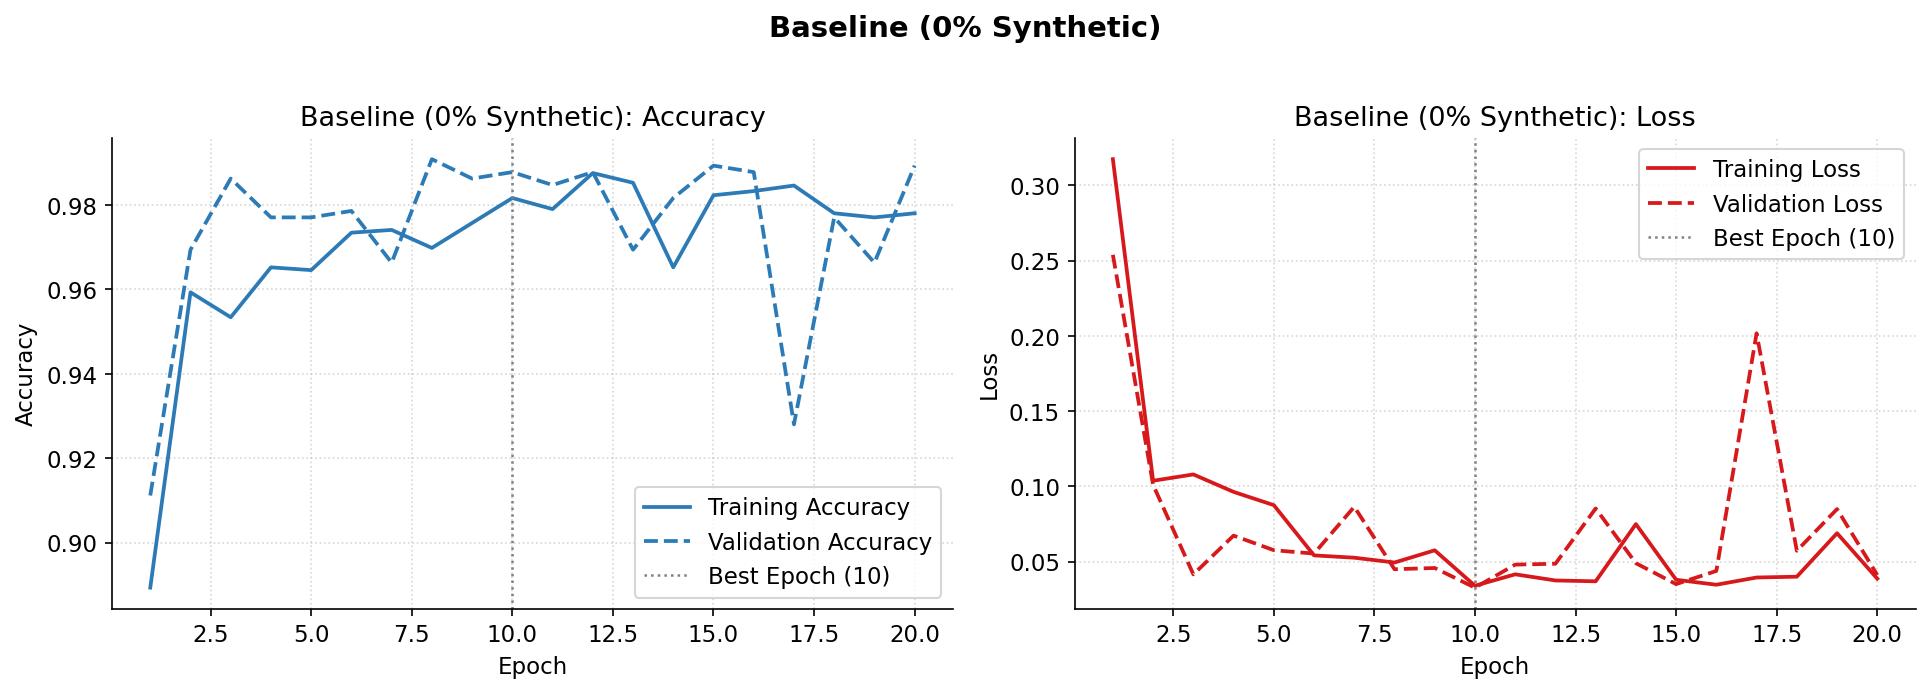

Figure saved: /content/drive/MyDrive/CarinthiaDataset/figures/fig_learning_curves_baseline.png


In [ ]:
# --- Step 6: Learning Curves ---
def plot_learning_curves(history, model_name="Baseline (0% Synthetic)"):
    acc      = history.history['accuracy']
    val_acc  = history.history['val_accuracy']
    loss     = history.history['loss']
    val_loss = history.history['val_loss']
    epochs   = range(1, len(acc) + 1)
    best_ep  = int(np.argmin(val_loss)) + 1

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    # Accuracy
    axes[0].plot(epochs, acc,     color=COLORS[0], label='Training Accuracy')
    axes[0].plot(epochs, val_acc, color=COLORS[0], linestyle='--', label='Validation Accuracy')
    axes[0].axvline(best_ep, color='gray', linestyle=':', linewidth=1.2, label=f'Best Epoch ({best_ep})')
    axes[0].set_title(f'{model_name}: Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()

    # Loss
    axes[1].plot(epochs, loss,     color=COLORS[1], label='Training Loss')
    axes[1].plot(epochs, val_loss, color=COLORS[1], linestyle='--', label='Validation Loss')
    axes[1].axvline(best_ep, color='gray', linestyle=':', linewidth=1.2, label=f'Best Epoch ({best_ep})')
    axes[1].set_title(f'{model_name}: Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()

    plt.suptitle(model_name, fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    save_path = f'/content/drive/MyDrive/CarinthiaDataset/figures/fig_learning_curves_baseline.png'
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, bbox_inches='tight')
    plt.show()
    print(f"Figure saved: {save_path}")

plot_learning_curves(history)


## 7. Evaluate the selected checkpoint

Load the checkpoint selected by validation loss and report class-wise metrics, Cohen's kappa, and a confusion matrix. These historical results reuse the subset that influenced model selection and should be interpreted accordingly.


21/21 ━━━━━━━━━━━━━━━━━━━━ 5s 182ms/step

--- Classification Report (Baseline – Original Data Only) ---
              precision    recall  f1-score   support

     class_1       0.70      0.88      0.78         8
     class_3       1.00      0.99      0.99       602
     class_4       0.91      0.95      0.93        43

    accuracy                           0.99       653
   macro avg       0.87      0.94      0.90       653
weighted avg       0.99      0.99      0.99       653

--- Cohen's Kappa (Baseline – Original Data Only) ---
κ = 0.9189


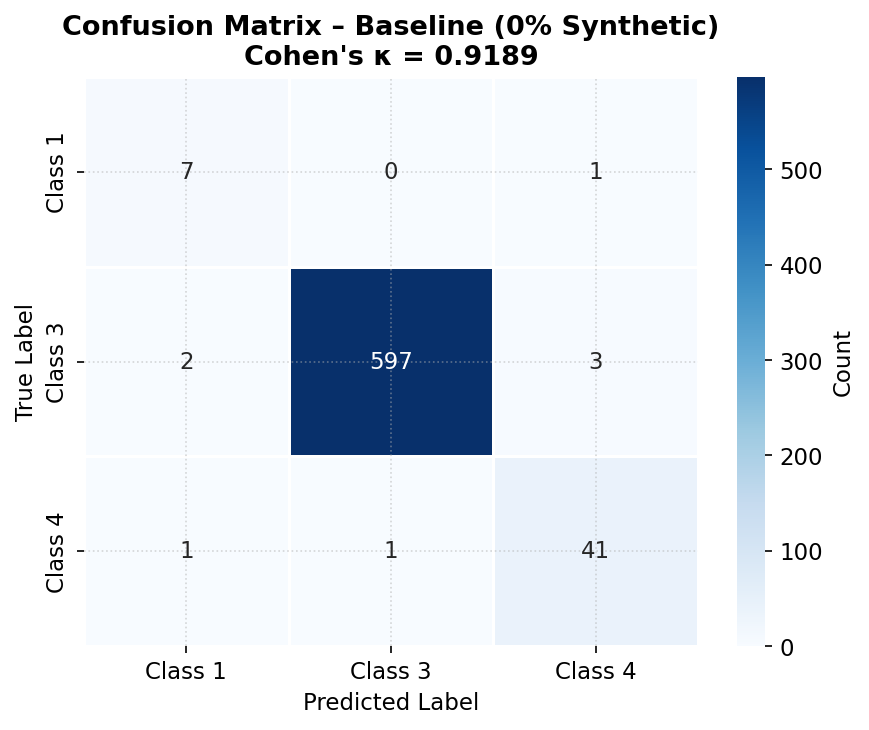

Figure saved: /content/drive/MyDrive/CarinthiaDataset/figures/fig_confusion_matrix_baseline.png
Cohen's Kappa: 0.9189


In [ ]:
# --- Step 7: Evaluation and Confusion Matrix ---
best_model = keras.models.load_model(checkpoint_path)

y_true       = np.concatenate([y for x, y in test_dataset], axis=0)
y_pred_probs = best_model.predict(test_dataset)
y_pred       = np.argmax(y_pred_probs, axis=1)

# Classification Report
print("\n--- Classification Report (Baseline – Original Data Only) ---")
print(classification_report(y_true, y_pred, target_names=class_names))

# Cohen's Kappa
kappa = cohen_kappa_score(y_true, y_pred)
print(f"--- Cohen's Kappa (Baseline – Original Data Only) ---")
print(f"κ = {kappa:.4f}")

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Class 1', 'Class 3', 'Class 4'],
            yticklabels=['Class 1', 'Class 3', 'Class 4'],
            linewidths=0.5, linecolor='white',
            cbar_kws={'label': 'Count'}, ax=ax)
ax.set_title(f'Confusion Matrix – Baseline (0% Synthetic)\nCohen\'s κ = {kappa:.4f}',
             fontweight='bold')
ax.set_xlabel('Predicted Label')
ax.set_ylabel('True Label')
plt.tight_layout()
save_path = '/content/drive/MyDrive/CarinthiaDataset/figures/fig_confusion_matrix_baseline.png'
os.makedirs(os.path.dirname(save_path), exist_ok=True)
plt.savefig(save_path, bbox_inches='tight')
plt.show()
print(f"Figure saved: {save_path}")
print(f"Cohen's Kappa: {kappa:.4f}")



## 8. Construct and evaluate prediction sets

Compute nonconformity scores as one minus the probability assigned to the true class. The archived threshold uses NumPy's default interpolated 99th percentile, without the finite-sample correction described in the thesis. Report empirical coverage and average set size at a nominal 99% target; these results do not establish the standard finite-sample coverage guarantee. Prediction sets may be empty.


Calibration complete. q_hat (99% coverage): 0.3268
Empirical coverage: 98.32%
Average set size:   0.988


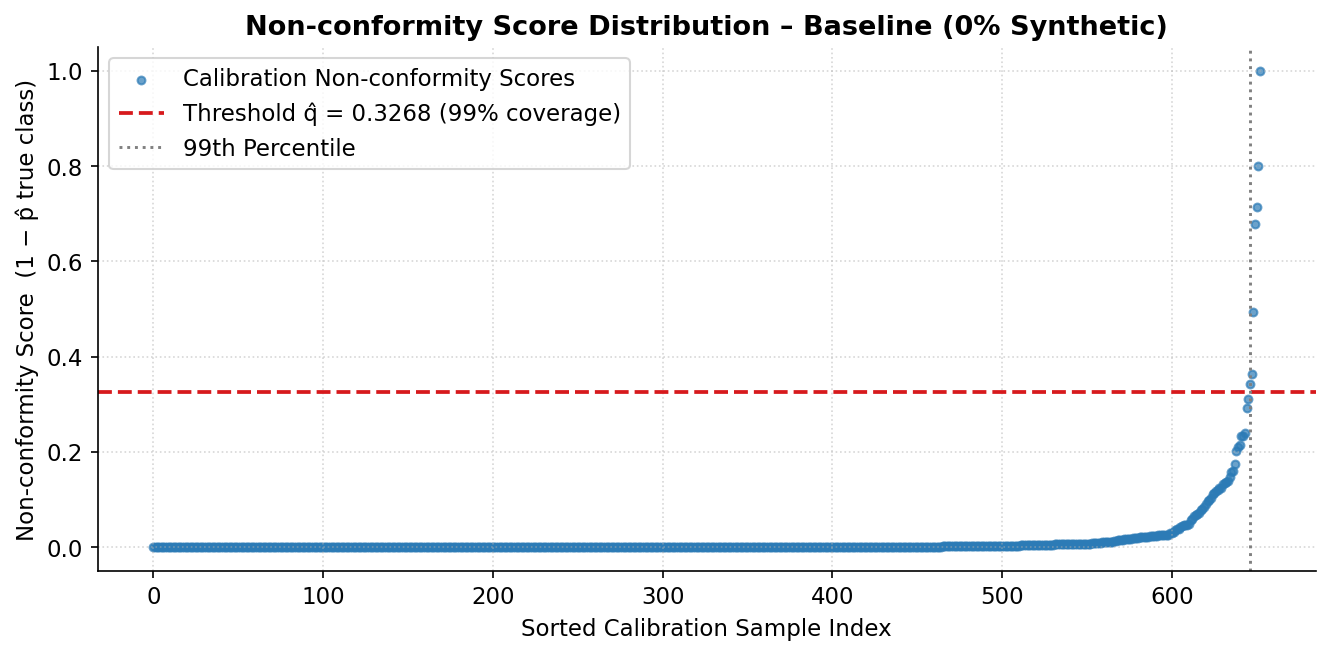

Figure saved: /content/drive/MyDrive/CarinthiaDataset/figures/fig_cp_scores_baseline.png


In [ ]:
# Archived calibration uses an interpolated percentile, not a finite-sample-corrected quantile.
# --- Step 8: Conformal Prediction ---
import numpy as np

X_cal_pool = np.concatenate([x for x, y in cal_dataset], axis=0)
y_cal_pool = np.concatenate([y for x, y in cal_dataset], axis=0)
X_test_pool= np.concatenate([x for x, y in test_dataset], axis=0)
y_test_pool= np.concatenate([y for x, y in test_dataset], axis=0)

y_probs_cal  = best_model.predict(X_cal_pool,  verbose=0)
y_probs_test = best_model.predict(X_test_pool, verbose=0)

scores_cal = 1 - y_probs_cal[np.arange(len(y_cal_pool)), y_cal_pool]

alpha  = 0.01
q_hat  = np.quantile(scores_cal, 1 - alpha)
print(f"Calibration complete. q_hat (99% coverage): {q_hat:.4f}")

prediction_sets = [np.where(probs >= 1 - q_hat)[0] for probs in y_probs_test]
coverage     = np.mean([y_test_pool[i] in prediction_sets[i] for i in range(len(y_test_pool))])
avg_set_size = np.mean([len(s) for s in prediction_sets])
print(f"Empirical coverage: {coverage:.2%}")
print(f"Average set size:   {avg_set_size:.3f}")

# --- Figure: Non-conformity Score Distribution ---
sorted_scores = np.sort(scores_cal)
n = len(sorted_scores)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(range(n), sorted_scores,
           s=14, color=COLORS[0], alpha=0.7, label='Calibration Non-conformity Scores')
ax.axhline(q_hat, color=COLORS[1], linestyle='--', linewidth=1.8,
           label=f'Threshold q̂ = {q_hat:.4f} (99% coverage)')
cutoff = int(n * (1 - alpha))
ax.axvline(cutoff, color='gray', linestyle=':', linewidth=1.4, label='99th Percentile')
ax.set_title('Non-conformity Score Distribution – Baseline (0% Synthetic)', fontweight='bold')
ax.set_xlabel('Sorted Calibration Sample Index')
ax.set_ylabel('Non-conformity Score  (1 − p̂ true class)')
ax.legend()
plt.tight_layout()
save_path = '/content/drive/MyDrive/CarinthiaDataset/figures/fig_cp_scores_baseline.png'
plt.savefig(save_path, bbox_inches='tight')
plt.show()
print(f"Figure saved: {save_path}")

results_baseline = {"model": "Baseline (0% Synth)",
                    "coverage": coverage, "avg_set_size": avg_set_size, "q_hat": q_hat}


## 9. Inspect minority-class precision and recall

Evaluate Class 1 against the remaining classes using a precision-recall curve and average precision. The saved classification report contains only eight Class 1 test examples.


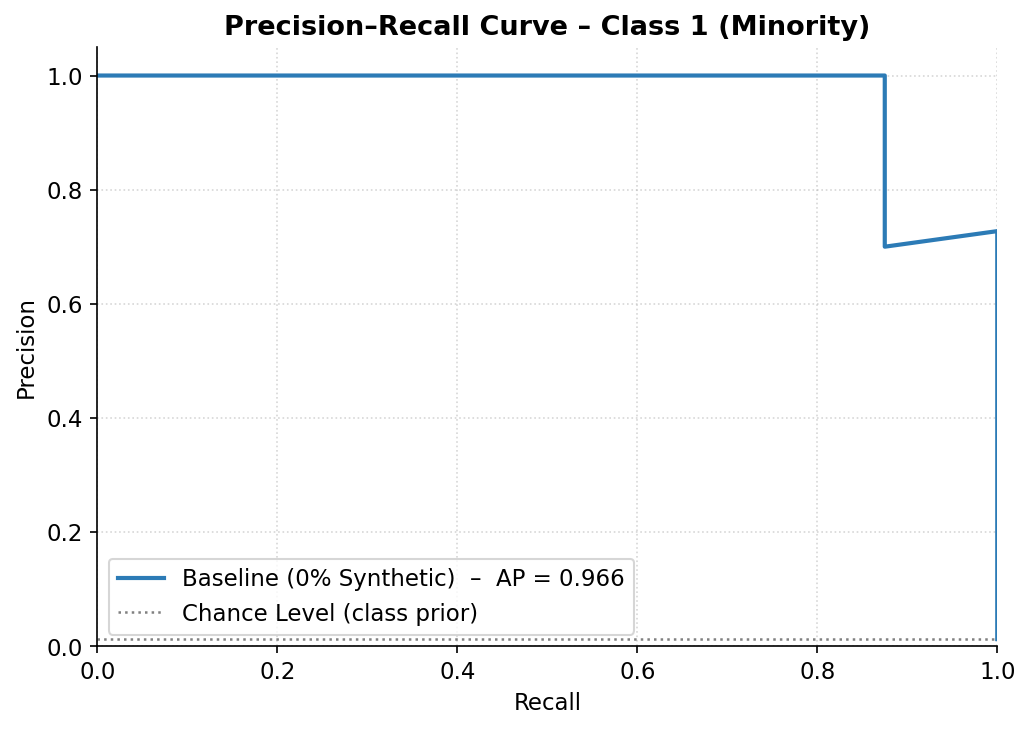

Average Precision (Class 1): 0.9659
Figure saved: /content/drive/MyDrive/CarinthiaDataset/figures/fig_pr_curve_baseline.png


In [ ]:
# Inspect the precision-recall trade-off for the minority class.
from sklearn.metrics import precision_recall_curve, average_precision_score

# Binary: Class 1 vs. rest
y_true_binary = (y_test_pool == 0).astype(int)   # class_1 has index 0
y_scores_c1   = y_probs_test[:, 0]               # softmax probability for class 1

precision, recall, thresholds = precision_recall_curve(y_true_binary, y_scores_c1)
ap = average_precision_score(y_true_binary, y_scores_c1)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(recall, precision, color=COLORS[0], linewidth=2,
        label=f'Baseline (0% Synthetic)  –  AP = {ap:.3f}')
ax.axhline(sum(y_true_binary)/len(y_true_binary), color='gray',
           linestyle=':', linewidth=1.2, label='Chance Level (class prior)')
ax.set_title('Precision–Recall Curve – Class 1 (Minority)', fontweight='bold')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.05])
ax.legend()
plt.tight_layout()
save_path = '/content/drive/MyDrive/CarinthiaDataset/figures/fig_pr_curve_baseline.png'
plt.savefig(save_path, bbox_inches='tight')
plt.show()
print(f"Average Precision (Class 1): {ap:.4f}")
print(f"Figure saved: {save_path}")


## 10. Check model interfaces and inspect examples

Check the output shape and softmax normalization, then display one example per class. Passing these checks does not validate generalization, data separation, or conformal coverage.


  SMOKE TEST & SANITY CHECK

[1/3] Smoke Test (random dummy input)...
      PASS – Output shape: (1, 3)

[2/3] Sanity Check A (softmax sums to 1)...
      PASS – Probability sum: 1.000000

[3/3] Sanity Check B (visual check on real test image)...


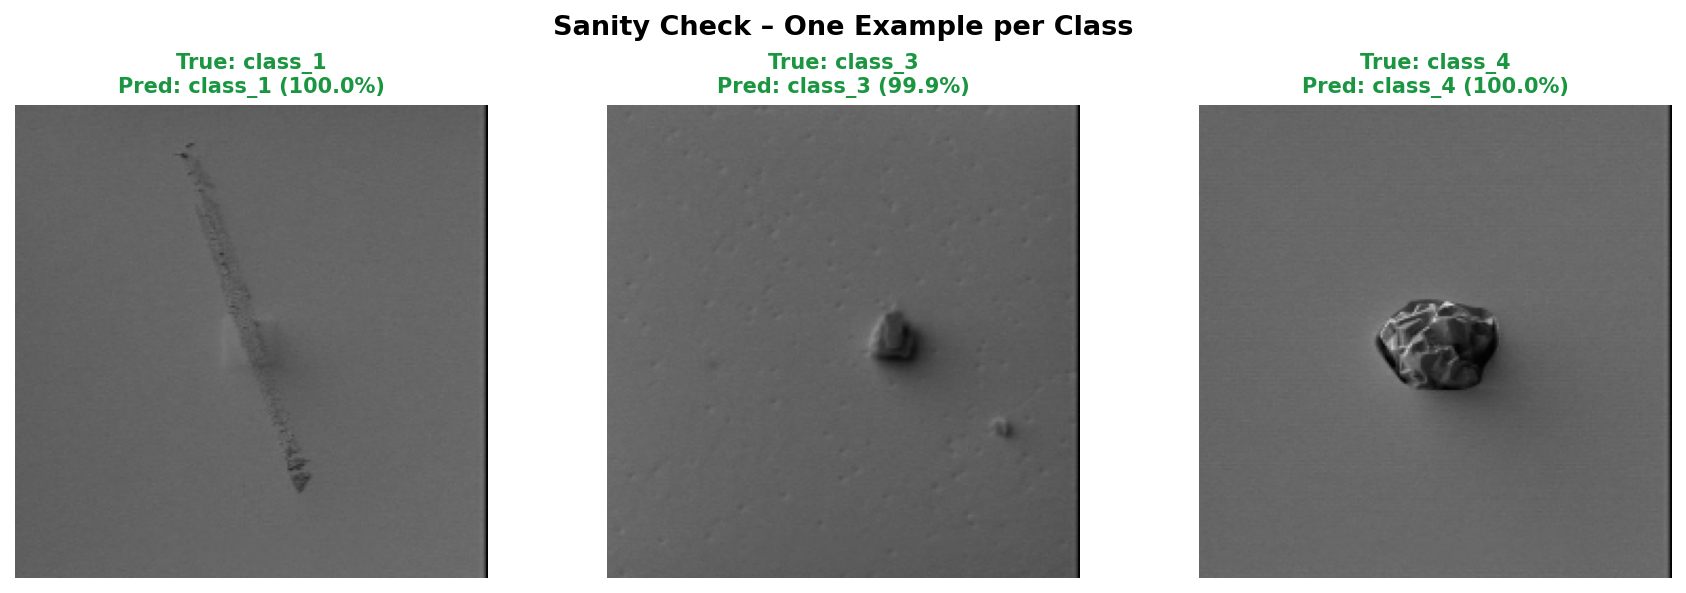


  ALL CHECKS PASSED


In [ ]:
# --- Step 10: Smoke Test & Sanity Check ---
import numpy as np
import matplotlib.pyplot as plt

print("=" * 50)
print("  SMOKE TEST & SANITY CHECK")
print("=" * 50)

# --- 1. Smoke Test: does the model accept a random input? ---
print("\n[1/3] Smoke Test (random dummy input)...")
dummy_input = np.random.rand(1, 224, 224, 3).astype(np.float32)
dummy_output = best_model.predict(dummy_input, verbose=0)
assert dummy_output.shape == (1, num_classes), "Output shape mismatch!"
print(f"      PASS – Output shape: {dummy_output.shape}")

# --- 2. Sanity Check A: do probabilities sum to 1? ---
print("\n[2/3] Sanity Check A (softmax sums to 1)...")
prob_sum = np.sum(dummy_output)
assert abs(prob_sum - 1.0) < 1e-5, f"Probabilities do not sum to 1: {prob_sum}"
print(f"      PASS – Probability sum: {prob_sum:.6f}")

# --- 3. Sanity Check B: visual check on one real test image ---
print("\n[3/3] Sanity Check B (visual check on real test image)...")

# Load one real image per class from the test set
X_test_sample = np.concatenate([x for x, y in test_dataset], axis=0)
y_test_sample = np.concatenate([y for x, y in test_dataset], axis=0)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for class_idx in range(num_classes):
    # Find first image of this class
    idx = np.where(y_test_sample == class_idx)[0][0]
    img = X_test_sample[idx]

    probs     = best_model.predict(img[np.newaxis], verbose=0)[0]
    pred_idx  = np.argmax(probs)
    pred_conf = probs[pred_idx]
    true_name = class_names[class_idx]
    pred_name = class_names[pred_idx]
    correct   = pred_idx == class_idx

    axes[class_idx].imshow(img.astype(np.uint8))
    axes[class_idx].axis('off')
    color = '#1a9641' if correct else '#d7191c'
    axes[class_idx].set_title(
        f"True: {true_name}\nPred: {pred_name} ({pred_conf:.1%})",
        fontsize=10, color=color, fontweight='bold')

plt.suptitle('Sanity Check – One Example per Class', fontweight='bold', fontsize=13)
plt.tight_layout()
save_path = '/content/drive/MyDrive/CarinthiaDataset/figures/fig_sanity_check_baseline.png'
plt.savefig(save_path, bbox_inches='tight')
plt.show()

print("\n" + "=" * 50)
print("  ALL CHECKS PASSED")
print("=" * 50)
